# 36 · Cost and latency: caps, caching, routing and the budget per ticket
Level L6 · Part 6 · core · ~35 min · builds on 03, 05, 15

## Goal
Price one support ticket from its calls, then cut the cost and the wait with three levers: a **cache** for steps whose answer does not change,
a **route** that sends easy work to a cheaper setting, and a **spend cap** per ticket. Each lever is measured, not guessed.

## Why it matters
An agent's bill grows with its calls, and its wait grows with the slowest step. A ticket that loops, or a policy that is pasted into every call,
costs many times the typical ticket. Teams that do not measure the cost per ticket cannot say which change saved money, or whether a new
feature doubled the bill.

| Without a budget | With a budget |
|---|---|
| A ticket's cost is unknown until the invoice | Each ticket has a price, from its calls and tokens |
| The same lookup is paid for each time it is asked | A cache answers the repeat, and the saving is counted |
| Every ticket gets the strongest setting | Easy tickets take the cheap route, measured against quality |

## The idea
Cost is **calls times tokens times price**. Latency is the sum of the steps on the path. A **cache** skips a step whose input has been seen before. A
**route** chooses a setting by the task, here the thinking budget. A **cap** stops a ticket when its spend passes the limit, as in lesson 05. The
prices used are the course's prices, the same as lesson 03.

## Picture
The drawing is made by `show_mermaid`, a course helper that draws a flowchart from the text you give it (the colours mark code steps in blue and
model steps in amber).

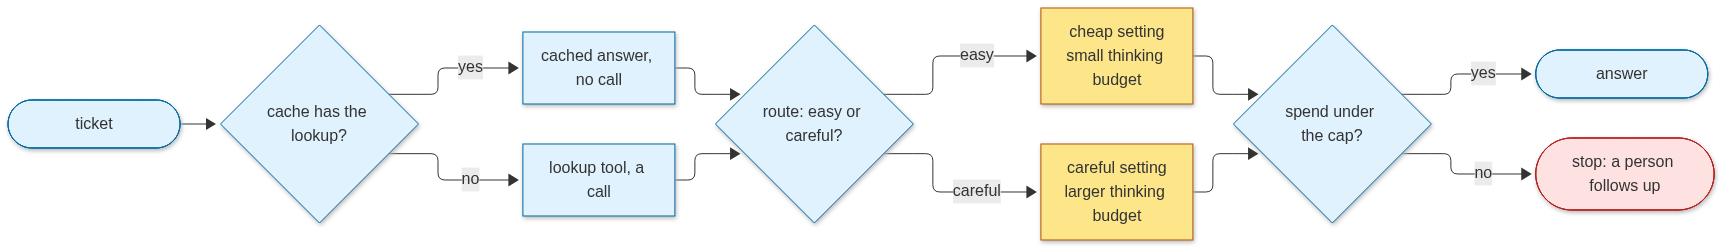

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  T(["ticket"]) --> C{"cache has the lookup?"}
  C -->|yes| H["cached answer, no call"]
  C -->|no| L["lookup tool, a call"]
  H --> R{"route: easy or careful?"}
  L --> R
  R -->|easy| E["cheap setting<br/>small thinking budget"]
  R -->|careful| K["careful setting<br/>larger thinking budget"]
  E --> B{"spend under the cap?"}
  K --> B
  B -->|yes| A(["answer"])
  B -->|no| S(["stop: a person follows up"])
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  classDef stop fill:#fee2e2,stroke:#b91c1c
  class E,K model
  class T,C,H,L,R,B,A code
  class S stop
""")

## Step by step

**Step 1 · the price of one ticket (no call).** The price of one call comes from its input and output tokens. A ticket is its calls added up. The
two printed lines price a typical ticket and a looping one, so the difference is visible before any change.

In [2]:
PRICE_IN, PRICE_OUT = 0.25, 1.50  # USD per 1M tokens, the same as lesson 03


def call_cost(tin: int, tout: int) -> float:
    return (tin * PRICE_IN + tout * PRICE_OUT) / 1_000_000


typical = [(1200, 60), (1300, 80)]  # two calls: the lookup request and the answer
looping = [(1200, 60)] * 12  # the same lookup asked again and again
for name, calls in (("typical ticket", typical), ("looping ticket", looping)):
    total = sum(call_cost(*c) for c in calls)
    print(f"{name:<16} {len(calls):>3} calls · ${total:.6f}")

typical ticket     2 calls · $0.000835
looping ticket    12 calls · $0.004680


**Step 2 · the cache: the same lookup is answered once (no model call).** The lookup is a node with a cache policy. The graph is compiled with a
cache. The first run runs the node; the second run, with the same input, reads the answer from the cache. A counter shows how many times the node
really ran. (`CachePolicy` and `InMemoryCache` are LangGraph's own cache classes: the policy says which node may be cached, and the cache holds the answers.)

In [3]:
import json
from pathlib import Path
from typing_extensions import TypedDict

from langgraph.cache.memory import InMemoryCache
from langgraph.graph import END, START, StateGraph
from langgraph.types import CachePolicy

ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]
RUNS = {"lookup": 0}


class LookupState(TypedDict):
    order_id: str
    row: dict


def lookup(state: LookupState) -> dict:
    RUNS["lookup"] += 1  # counts the real runs of this step
    return {"row": ORDERS.get(state["order_id"], {"error": "no order"})}

The graph has one node, `lookup`, wired from start to end. It is compiled with the cache, then asked twice with the same order.

In [4]:
cached_graph = StateGraph(LookupState)
cached_graph.add_node("lookup", lookup, cache_policy=CachePolicy())  # a deterministic step: safe to cache
cached_graph.add_edge(START, "lookup").add_edge("lookup", END)
cached_app = cached_graph.compile(cache=InMemoryCache())
for attempt in ("first ask", "same ask again"):
    cached_app.invoke({"order_id": "1003", "row": {}})
    print(f"{attempt:<16} lookup ran {RUNS['lookup']} time(s) so far")

first ask        lookup ran 1 time(s) so far
same ask again   lookup ran 1 time(s) so far


A cache is right only while the answer does not change. Here the order is marked delivered in the data after the first ask. The cache still
returns the old row, and the step does not run again.

In [5]:
ORDERS = {**ORDERS, "1003": {**ORDERS["1003"], "status": "delivered"}}  # the data changes
print("cache says:    ", cached_app.invoke({"order_id": "1003", "row": {}})["row"]["status"])
print("data now says: ", ORDERS["1003"]["status"], "· lookup ran", RUNS["lookup"], "time(s)")

cache says:     lost
data now says:  delivered · lookup ran 1 time(s)


**Step 3 · the route: two settings, measured (2 model calls).** Two settings answer the same classifier question: a small thinking budget and a
larger one. In an app, a label from the first step would pick one of them; here both run, so the cost and the time of each are measured. The two
helpers in the next cell: `llm_replay` saves each model answer the first time it runs, so later runs replay it offline with no key, and `get_llm()`
is the course's model setup from `llm_setup.py`. The token counts are read from the replies.

In [6]:
import llm_replay
llm_replay.start("36_cost-and-latency")

import time
from llm_setup import get_llm

ROUTES = {"easy": get_llm(thinking_budget=0), "careful": get_llm(thinking_budget=1024)}
TICKET = "Order 1003 never arrived. Is this a status question or a refund question? One word."
measured = {}
for name, model in ROUTES.items():
    start = time.perf_counter()
    reply = model.invoke(TICKET)
    ms = round((time.perf_counter() - start) * 1000)
    u = reply.usage_metadata
    measured[name] = (u["input_tokens"], u["output_tokens"], ms, reply.text.strip()[:40])
    print(f"{name:<8} answer={measured[name][3]!r} · {u['input_tokens']} in, {u['output_tokens']} out · {ms} ms · "
          f"${call_cost(u['input_tokens'], u['output_tokens']):.6f}")
llm_replay.stop()  # the last model call of this lesson

LLM mode: replay (36_cost-and-latency.yaml)


Gemini on Vertex AI · API key loaded: True
Gemini on Vertex AI · API key loaded: True
easy     answer='Status' · 22 in, 1 out · 75 ms · $0.000007
careful  answer='Status' · 22 in, 419 out · 4 ms · $0.000634


**Step 4 · the spend cap per ticket (no call).** A ticket stops when its spend passes the cap, checked after each call, as in lesson 05. The cap
uses the measured cost of the careful route, so the limit is set from a real number.

In [7]:
careful_cost = call_cost(measured["careful"][0], measured["careful"][1])
CAP = 3 * careful_cost  # a cap of three careful calls per ticket
spent = 0.0
for step in range(1, 10):
    spent += careful_cost
    if spent > CAP:
        print(f"stop at call {step}: ${spent:.6f} is over the cap of ${CAP:.6f}; a person follows up")
        break
else:
    print("no stop")

stop at call 4: $0.002536 is over the cap of $0.001902; a person follows up


**Step 5 · the latency budget (no call).** The wait is the sum of the steps on the path, so the budget is set per step. The check compares each
route's time with the budget a customer will wait for. The times come from the replay on your machine, not from the live model: a record with a
key gives the real waits, and the check is the pattern to copy.

In [8]:
BUDGET_MS = 3000
for name, (tin, tout, ms, _) in measured.items():
    print(f"{name:<8} {ms:>6} ms · within the {BUDGET_MS} ms budget: {ms <= BUDGET_MS}")

easy         75 ms · within the 3000 ms budget: True
careful       4 ms · within the 3000 ms budget: True


## At real scale
- **Cost is read from the traces, per task and per tenant.** Count the cache-read tokens too, or a cached call looks like a full-price call. Teams
  alert when a ticket passes its budget → lesson 33 (observability).
- **Budgets sit at the gateway, not inside each agent.** A per-tenant limit stops one customer's loop from spending another customer's money → lesson 37
  (serving and the enterprise map).
- **Provider prices change within months.** Re-check the price table on the day you set a budget, and re-measure the cheap route's quality before you switch
  it → lesson 32 (evals in CI).

## Decision guide
| Situation | Approach | Why |
|---|---|---|
| The same lookup is asked again with the same input | cache the node (`CachePolicy`) | the answer is the same, so the repeat costs nothing |
| The data behind a lookup can change (an order's status) | cache only what does not change, or expire it | a cache returns the old row, as Step 2 showed |
| An easy classification (status or refund) | the cheap setting, after its answers match the careful route on the golden set | cheap is only cheap if the answers stay right |
| A ticket can loop or grow expensive | a per-ticket cap in code, checked after each call | the cap stops the loop and hands the ticket to a person |
| A step is slow | budget each step, and measure it live | the customer waits for the sum of the steps |

## What just happened
- Step 1: the typical ticket costs $0.000835 in 2 calls; the looping one costs $0.004680 in 12 calls, about 5.6 times as much.
- Step 2: two asks, and the node ran once (`lookup ran 1`). After the data changed, the cache still returned the old status, "lost".
- Step 3: both settings answered "Status". The easy one cost $0.000007 (1 output token) and the careful one $0.000634 (419 output tokens), about 90 times as much.
- Step 4: the cap of $0.001902 (three careful calls) stopped the ticket at call 4, at $0.002536.
- Step 5: both replay times are within the 3000 ms budget; they are replay times, not live ones.

## Common mistakes
1. **Caching a step that changes.** A stale answer is a wrong answer, not an error, so no exception shows it. Step 2 showed the wrong status. Cache
   lookups whose answer does not change, not replies.
2. **Choosing the cheap route without measuring quality.** Cheap is only cheap if the answers are still right on the golden set.
3. **A cap set from a guess.** Set the cap from the measured cost of a real ticket, as Step 4 does.

## Try it
Write `ticket_cost(calls)` that takes a list of `(input_tokens, output_tokens)` pairs and returns the total cost in dollars, using `call_cost`.
Test it on `[(1000, 100)]` and on `[(1000, 100), (500, 50)]`. No model call is needed.

In [9]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [10]:
def ticket_cost(calls: list[tuple[int, int]]) -> float:
    return sum(call_cost(tin, tout) for tin, tout in calls)


print(f"{ticket_cost([(1000, 100)]):.6f}", f"{ticket_cost([(1000, 100), (500, 50)]):.6f}")

0.000400 0.000600


## Key terms
- **Cache** — a store of past answers; a repeat with the same input is answered from it, without running the step again.
- **Cache hit** — a request answered from the cache.
- **Latency** — the time a customer waits; for an agent, the sum of its steps.
- **Route** — the choice of which setting or model handles a piece of work, here by the task.
- **Spend cap** — a limit on the money one task may use, checked after each call.
- **Thinking budget** — how many tokens the model may spend reasoning before it answers; this lesson uses 0 and 1024.
- **Token price** — the cost per million input and output tokens, the basis of every cost in this lesson.

## Recap
- A ticket's cost is its calls, times tokens, times price. Measure it before you change anything.
- A node cache skips a deterministic step; a route picks a cheaper setting for easy work; a cap stops a ticket that spends too much.
- Latency is the sum of the steps, so budget each one.

**Interview:** "The support agent's bill doubled after a release. Where do you look first?" Strong answer: "I compare the cost per ticket before and after,
and find the calls that changed in number or size. Then I check whether a step that could be cached is being repeated, and whether the cap is still in place."